# Challenge Sprint 4 — Modelagem linear

**Classificação da classe de energia renovável (`Energy_Class`)**

**Integrantes:** Rafael Laprega Gontijo Magalhaes (RM 561975); Gustavo Torres de Oliveira (RM 572952); Lucas Furquim Lima (RM 568690); Diogo Chiaradia Santos (RM 570246).

Este notebook é independente: não precisa da pasta `src/`. Ele apresenta a preparação dos dados, a análise de correlação, a Regressão Logística, dois cenários de treino/teste, métricas e matrizes de confusão.

**No Colab:** clique em **Ambiente de execução → Executar tudo**. Na primeira célula de código, selecione o arquivo `renewable_energy_production_dataset.csv` quando o upload for solicitado.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

RANDOM_STATE = 42
TARGET = 'Energy_Class'
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / 'data' / 'renewable_energy_production_dataset.csv'
OUTPUT_DIR = PROJECT_ROOT / 'outputs'
OUTPUT_DIR.mkdir(exist_ok=True)

# No Colab, o único arquivo necessário é o CSV.
if 'google.colab' in sys.modules and not DATA_PATH.exists():
    from google.colab import files
    print('Selecione o arquivo renewable_energy_production_dataset.csv')
    uploaded = files.upload()
    if not uploaded:
        raise FileNotFoundError('Nenhum CSV foi enviado. Execute esta célula novamente.')
    DATA_PATH.parent.mkdir(exist_ok=True)
    filename = next(iter(uploaded))
    DATA_PATH.write_bytes(uploaded[filename])

if not DATA_PATH.exists():
    raise FileNotFoundError(f'CSV não encontrado: {DATA_PATH.resolve()}')

print(f'Arquivo carregado: {DATA_PATH}')

Arquivo carregado: /home/diogocs/challenge-sprint-4/data/renewable_energy_production_dataset.csv


## 1. Leitura e exploração dos dados

Verificamos as dimensões, os tipos das colunas, os valores ausentes e a distribuição da variável-alvo. A base usada no trabalho contém 1.000 registros e três classes.

In [2]:
df = pd.read_csv(DATA_PATH)
if TARGET not in df.columns:
    raise ValueError(f'A coluna {TARGET} não existe no CSV.')
df = df.dropna(subset=[TARGET]).reset_index(drop=True)

print(f'Dimensões: {df.shape[0]} linhas × {df.shape[1]} colunas')
display(df.head())
display(pd.DataFrame({'tipo': df.dtypes.astype(str), 'valores_ausentes': df.isna().sum()}))
print('Distribuição da variável-alvo:')
display(df[TARGET].value_counts().rename('quantidade').to_frame())

Dimensões: 1000 linhas × 11 colunas


,Region,Energy_Source,Temperature_C,Wind_Speed_m_s,Solar_Radiation_kWh_m2,Rainfall_mm,Season,Efficiency_Ratio,Lagged_Production_MWh,Combined_Weather_Index,Energy_Class
0,North,Hydro,13.820937,14.362462,8.834648,3.350827,Winter,125.449109,1419.514155,1.565158,Medium
1,North,Solar,36.972782,19.110474,4.483191,48.767157,Winter,16.325089,4769.329958,0.621331,Low
2,East,Hydro,33.972875,0.364652,5.104325,40.848695,Winter,155.637061,1005.077719,0.156378,High
3,South,Solar,-2.965160,3.915560,6.265925,42.627371,Spring,675.516566,6294.250931,-5.180996,High
4,North,Wind,-3.813486,0.151257,9.263826,46.898262,Spring,626.048277,5550.263638,-3.346412,Medium


,tipo,valores_ausentes
Region,str,0
Energy_Source,str,0
Temperature_C,float64,0
Wind_Speed_m_s,float64,0
Solar_Radiation_kWh_m2,float64,0
Rainfall_mm,float64,0
Season,str,0
Efficiency_Ratio,float64,0
Lagged_Production_MWh,float64,0
Combined_Weather_Index,float64,0


Distribuição da variável-alvo:


,quantidade
Energy_Class,
High,486
Medium,336
Low,178


## 2. Preparação e correlação

A variável-alvo é codificada com `LabelEncoder`. Para a análise exploratória de correlação, os preditores categóricos são convertidos em indicadores one-hot.

**Importante:** os números dados às classes não representam uma ordem real. Por isso, a correlação com o alvo codificado é apenas uma referência e não é usada sozinha para excluir variáveis.

Codificação do alvo: {'High': np.int64(0), 'Low': np.int64(1), 'Medium': np.int64(2)}
Preditores utilizados: ['Region', 'Energy_Source', 'Temperature_C', 'Wind_Speed_m_s', 'Solar_Radiation_kWh_m2', 'Rainfall_mm', 'Season', 'Efficiency_Ratio', 'Lagged_Production_MWh', 'Combined_Weather_Index']
Maiores correlações absolutas com o alvo codificado:


,correlação
Efficiency_Ratio,-0.166829
Region_North,0.046544
Rainfall_mm,0.045790
Region_South,-0.041531
Season_Spring,-0.040795
Energy_Source_Hydro,-0.039371
Energy_Source_Solar,0.032235
Season_Monsoon,0.029507
Region_East,-0.028396
Temperature_C,0.028338


Pares com |correlação| >= 0,85: 0


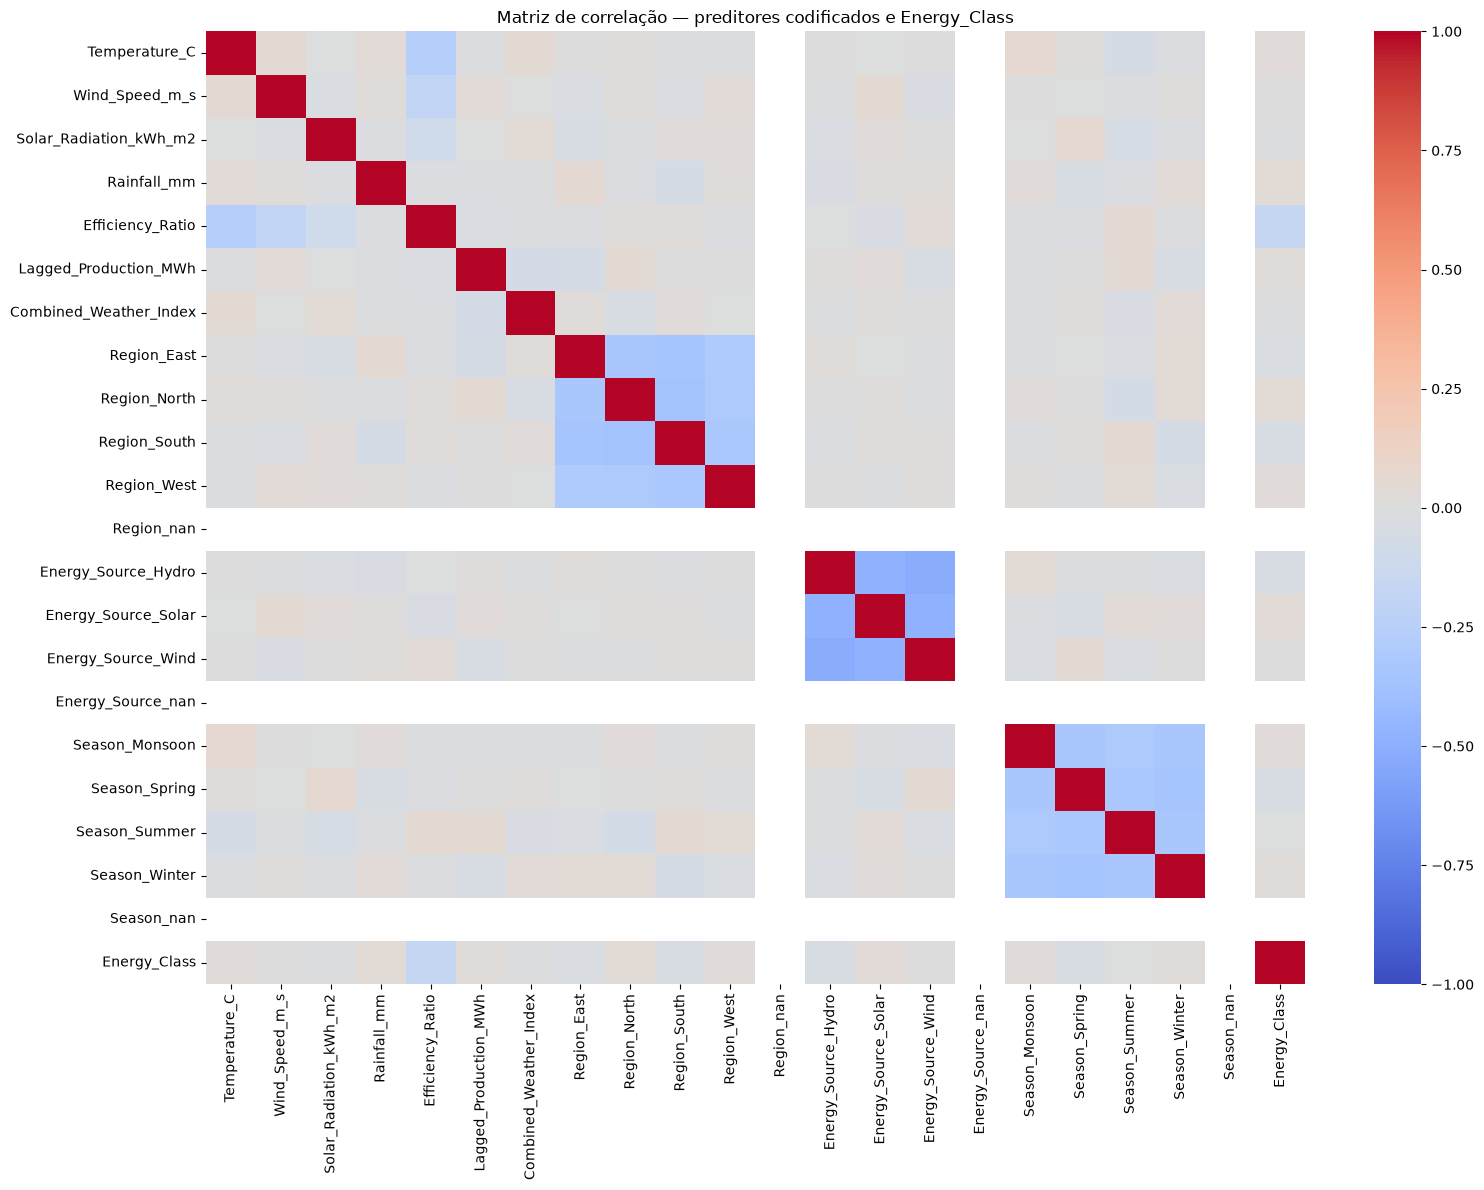

In [3]:
target_encoder = LabelEncoder()
y = target_encoder.fit_transform(df[TARGET].astype(str))
X = df.drop(columns=[TARGET]).copy()
empty_columns = X.columns[X.isna().all()].tolist()
X = X.drop(columns=empty_columns)

print('Codificação do alvo:', dict(zip(target_encoder.classes_, target_encoder.transform(target_encoder.classes_))))
print('Preditores utilizados:', list(X.columns))

correlation_data = pd.get_dummies(X, dummy_na=True, dtype=float)
correlation_data[TARGET] = y
correlation = correlation_data.corr(method='pearson', numeric_only=True)
correlation.to_csv(OUTPUT_DIR / 'correlation_matrix.csv', encoding='utf-8')

target_correlations = correlation[TARGET].drop(TARGET).dropna()
target_correlations = target_correlations.reindex(target_correlations.abs().sort_values(ascending=False).index)
print('Maiores correlações absolutas com o alvo codificado:')
display(target_correlations.head(10).to_frame('correlação'))

upper = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool))
high_pairs = upper.stack()
high_pairs = high_pairs[high_pairs.abs() >= 0.85]
print('Pares com |correlação| >= 0,85:', len(high_pairs))

fig, ax = plt.subplots(figsize=(16, 12))
sns.heatmap(correlation, cmap='coolwarm', vmin=-1, vmax=1, center=0, ax=ax)
ax.set_title('Matriz de correlação — preditores codificados e Energy_Class')
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'correlation_heatmap.png', dpi=180, bbox_inches='tight')
plt.show()

## 3. Modelo linear: Regressão Logística

Para cada classe, a Regressão Logística calcula um escore linear da forma `z = wᵀx + b`. No problema multiclasse, esses escores são convertidos em probabilidades e a fronteira entre duas classes é linear no espaço dos atributos.

O pipeline faz imputação, padronização das variáveis numéricas e one-hot encoding das categóricas. Essas transformações são ajustadas somente no conjunto de treino, evitando vazamento de dados.

In [4]:
numeric_columns = X.select_dtypes(include=[np.number, 'bool']).columns.tolist()
categorical_columns = [column for column in X.columns if column not in numeric_columns]

transformers = []
if numeric_columns:
    numeric_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])
    transformers.append(('numeric', numeric_pipeline, numeric_columns))
if categorical_columns:
    categorical_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])
    transformers.append(('categorical', categorical_pipeline, categorical_columns))

preprocessor = ColumnTransformer(transformers=transformers)
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
print('Variáveis numéricas:', numeric_columns)
print('Variáveis categóricas:', categorical_columns)
model

Variáveis numéricas: ['Temperature_C', 'Wind_Speed_m_s', 'Solar_Radiation_kWh_m2', 'Rainfall_mm', 'Efficiency_Ratio', 'Lagged_Production_MWh', 'Combined_Weather_Index']
Variáveis categóricas: ['Region', 'Energy_Source', 'Season']


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, 

## 4. Treinamento e avaliação em dois cenários

- **Cenário 1:** 60% para treino e 40% para teste.
- **Cenário 2:** 85% para treino e 15% para teste.

As divisões usam a mesma semente (`random_state=42`) e estratificação. Também comparamos o modelo com uma baseline que sempre prevê a classe mais frequente.


Cenário 1: 600 treino / 400 teste
              precision    recall  f1-score   support

        High     0.7603    0.9436    0.8421       195
         Low     0.6667    0.4507    0.5378        71
      Medium     0.6545    0.5373    0.5902       134

    accuracy                         0.7200       400
   macro avg     0.6938    0.6439    0.6567       400
weighted avg     0.7083    0.7200    0.7037       400



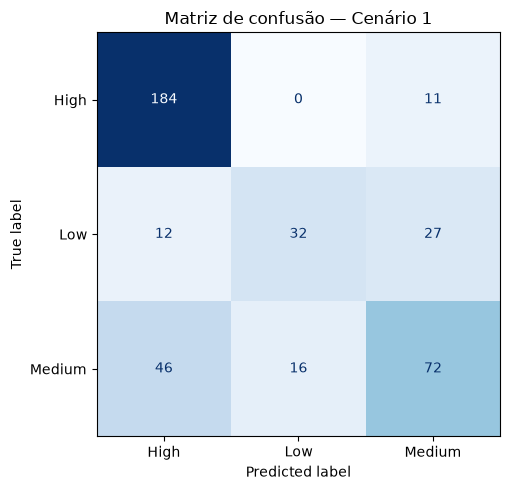


Cenário 2: 850 treino / 150 teste
              precision    recall  f1-score   support

        High     0.8095    0.9315    0.8662        73
         Low     0.8571    0.6667    0.7500        27
      Medium     0.7333    0.6600    0.6947        50

    accuracy                         0.7933       150
   macro avg     0.8000    0.7527    0.7703       150
weighted avg     0.7927    0.7933    0.7882       150



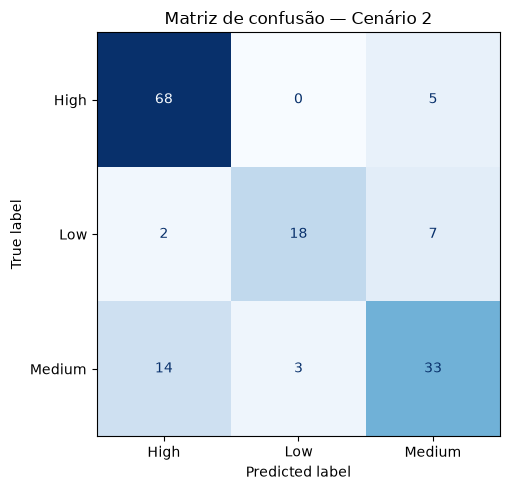

,cenário,treino,teste,acurácia,baseline_majoritária,precisão_weighted,recall_weighted,precisão_macro,recall_macro
0,Cenário 1,600,400,0.7200,0.4875,0.7083,0.7200,0.6938,0.6439
1,Cenário 2,850,150,0.7933,0.4867,0.7927,0.7933,0.8000,0.7527


In [5]:
def evaluate(test_size, scenario):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=RANDOM_STATE, stratify=y
    )
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    baseline = DummyClassifier(strategy='most_frequent')
    baseline.fit(X_train, y_train)
    baseline_predictions = baseline.predict(X_test)

    labels = np.arange(len(target_encoder.classes_))
    metrics = {
        'cenário': scenario,
        'treino': len(y_train),
        'teste': len(y_test),
        'acurácia': accuracy_score(y_test, predictions),
        'baseline_majoritária': accuracy_score(y_test, baseline_predictions),
        'precisão_weighted': precision_score(y_test, predictions, average='weighted', zero_division=0),
        'recall_weighted': recall_score(y_test, predictions, average='weighted', zero_division=0),
        'precisão_macro': precision_score(y_test, predictions, average='macro', zero_division=0),
        'recall_macro': recall_score(y_test, predictions, average='macro', zero_division=0)
    }
    print(f'\n{scenario}: {len(y_train)} treino / {len(y_test)} teste')
    print(classification_report(y_test, predictions, labels=labels, target_names=target_encoder.classes_, digits=4, zero_division=0))

    fig, ax = plt.subplots(figsize=(7, 5))
    cm = confusion_matrix(y_test, predictions, labels=labels)
    ConfusionMatrixDisplay(cm, display_labels=target_encoder.classes_).plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(f'Matriz de confusão — {scenario}')
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / f'confusion_matrix_{scenario.lower().replace(" ", "_")}.png', dpi=180, bbox_inches='tight')
    plt.show()
    return metrics

results = pd.DataFrame([
    evaluate(0.40, 'Cenário 1'),
    evaluate(0.15, 'Cenário 2')
])
results.to_csv(OUTPUT_DIR / 'metrics_comparison.csv', index=False)
display(results.round(4))

## 5. Interpretação dos resultados

Nos resultados reproduzíveis deste trabalho, a acurácia foi **0,7200** no cenário 60/40 e **0,7933** no cenário 85/15. As baselines majoritárias ficaram em **0,4875** e **0,4867**, respectivamente.

O modelo supera a baseline, mas as métricas por classe e as matrizes de confusão mostram que ele ainda erra mais as classes **Low** e **Medium**. O segundo cenário apresentou métricas maiores neste experimento, porém isso não prova que ele seja sempre melhor: os tamanhos dos testes são diferentes. Como próximo passo, a validação cruzada estratificada daria uma comparação mais estável.

Os arquivos gerados ficam na pasta `outputs/`: heatmap, matriz de correlação em CSV, matrizes de confusão e tabela comparativa.